#     # Q3: Can a simple regression model beat a naive forecast?

In [6]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Visual configurations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df_final = pd.read_parquet("../data/processed/pld_se_co_monthly.parquet")

# 1. Target at month t, predictors from month t-1 (information available before the month starts)
df_q3 = pd.DataFrame(index=df_final.index)
df_q3["pld"] = df_final["pld_se_co"]
df_q3["pld_lag1"] = df_final["pld_se_co"].shift(1)
df_q3["ear_lag1"] = df_final["ear_seco_mwmes"].shift(1) / 1000
df_q3["ena_lag1"] = df_final["ena_seco_mwmed"].shift(1) / 1000  

# 2. The first month has no previous month, so it is dropped
df_q3 = df_q3.dropna()

features_1 = ["ear_lag1", "ena_lag1"]
features_2 = ["pld_lag1", "ear_lag1", "ena_lag1"]

print(f"Months available: {len(df_q3)}")
display(df_q3.head())

Months available: 104


,pld,pld_lag1,ear_lag1,ena_lag1
date,,,,
2017-02-01,128.43,121.44,69.836613,43.990903
2017-03-01,216.24,128.43,80.383464,49.413429
2017-04-01,371.47,216.24,83.858097,45.626032
2017-05-01,411.49,371.47,84.446433,39.045967
2017-06-01,124.70,411.49,85.763161,38.930387


* The dataset has 104 months: the original 105 minus the first month (January 2017), which has no previous month to provide the lagged values.
* The lag works as intended. Each `pld_lag1` equals the `pld` of the row above (for example, the March PLD of 216.24 appears as the lag of April), and the first row (February 2017) uses the EAR and ENA of January 2017 (EAR of ~69.8 thousand MWmês and ENA of ~44.0 thousand MWmed).
* EAR and ENA are expressed in thousands of MWmês and MWmed, the same scale used in the regression of Q2.

In [8]:
# === Q3: WALK-FORWARD FORECAST ===

# Train on 2017-2020 first, then forecast 2021 onward, one month at a time
first_test_month = "2021-01-01"
test_dates = df_q3.loc[first_test_month:].index

results = []

for date in test_dates:
    # 1. Training data: only months BEFORE the month being forecast
    train = df_q3.loc[df_q3.index < date]
    test_row = df_q3.loc[[date]]

    # 2. Floor protection: the forecast cannot go below the lowest PLD seen so far
    floor = train["pld"].min()

    # 3. Naive forecast: this month's PLD = previous month's PLD
    naive_pred = test_row["pld_lag1"].iloc[0]

    # 4. Model 1: EAR and ENA of the previous 
    model_1 = LinearRegression()
    model_1.fit(train[features_1], train["pld"])
    pred_1 = model_1.predict(test_row[features_1])[0]
    if pred_1 < floor:
        pred_1 = floor

    # 5. Model 2: previous PLD + EAR + ENA
    model_2 = LinearRegression()
    model_2.fit(train[features_2], train["pld"])
    pred_2 = model_2.predict(test_row[features_2])[0]
    if pred_2 < floor:
        pred_2 = floor

    results.append({
        "date": date,
        "actual": test_row["pld"].iloc[0],
        "naive": naive_pred,
        "model_1": pred_1,
        "model_2": pred_2,
    })

df_results = pd.DataFrame(results).set_index("date")
print(f"Forecasted months: {len(df_results)}")
display(df_results.head())

Forecasted months: 57


,actual,naive,model_1,model_2
date,,,,
2021-01-01,242.72,267.49,319.266342,253.244042
2021-02-01,165.98,242.72,238.772507,207.953298
2021-03-01,109.02,165.98,201.277594,155.078736
2021-04-01,132.63,109.02,180.775126,128.582924
2021-05-01,218.70,132.63,249.038950,184.876503


* The walk-forward produces 57 one-month-ahead forecasts, from January 2021 to September 2025. The first model is trained only on 2017-2020 and is retrained every month with all the data available up to the previous month.
* The `naive` column is the previous month's observed PLD (for example, the naive forecast for February, 242.72, is the observed PLD of January).
* In the first five months, Model 2 (previous PLD + EAR + ENA) has a smaller absolute error than the naive forecast in all of them (mean absolute error of ~27 vs ~54 R$/MWh), while Model 1 (EAR + ENA only) beats the naive forecast in only two (February and May) and has a larger average error (~64 R$/MWh).
* This is only a first look at 5 of 57 months: the conclusion depends on the full evaluation table, which also needs to be checked without 2022-2024, when the PLD stays flat at the floor and favors the naive forecast.

,Sample,Model,N,MAE,RMSE,RMSE gain vs naive (%)
0,2021-2025,Naive (previous month),57,46.72,95.37,0.00
1,2021-2025,Model 1: EAR + ENA (lag 1),57,104.61,128.44,-34.68
2,2021-2025,Model 2: + previous PLD,57,71.88,99.95,-4.81
3,Excl. 2022-2024,Naive (previous month),21,81.46,120.73,0.00
4,Excl. 2022-2024,Model 1: EAR + ENA (lag 1),21,131.05,154.60,-28.06
5,Excl. 2022-2024,Model 2: + previous PLD,21,80.39,112.47,6.84


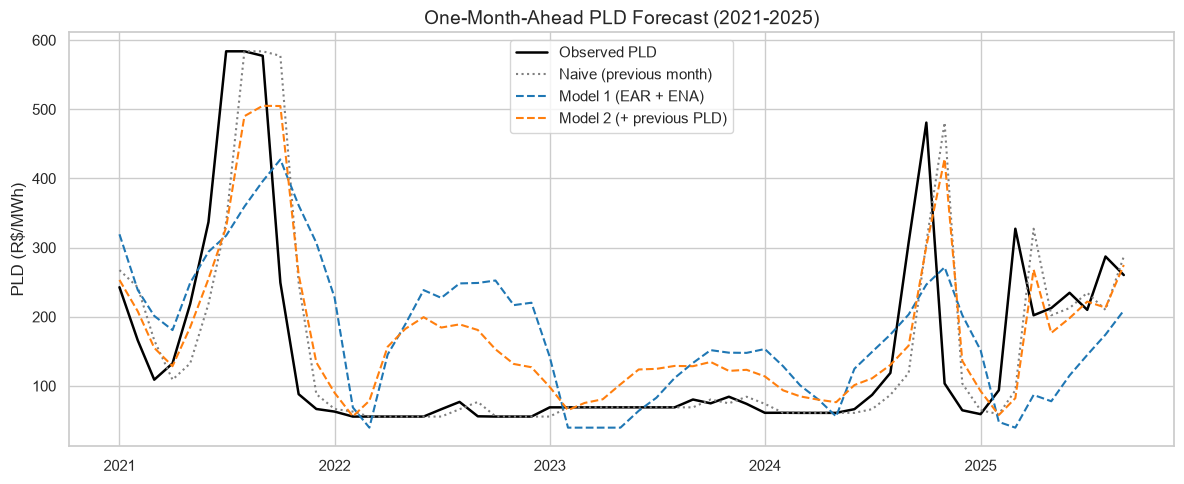

In [ ]:
# --- Q3: EVALUATION ---

def build_table(df_sub, label):
    """
    Compute MAE, RMSE and the RMSE gain over the naive forecast.
    """

    naive_rmse = np.sqrt(mean_squared_error(df_sub["actual"], df_sub["naive"]))
    names = {
        "naive": "Naive (previous month)",
        "model_1": "Model 1: EAR + ENA (lag 1)",
        "model_2": "Model 2: + previous PLD",
    }
    rows = []
    for column, model_name in names.items():
        mae = mean_absolute_error(df_sub["actual"], df_sub[column])
        rmse = np.sqrt(mean_squared_error(df_sub["actual"], df_sub[column]))
        gain = (naive_rmse - rmse) / naive_rmse * 100
        rows.append({
            "Sample": label,
            "Model": model_name,
            "N": len(df_sub),
            "MAE": mae,
            "RMSE": rmse,
            "RMSE gain vs naive (%)": gain,
        })
        
    return pd.DataFrame(rows)

# 1. Full test period (2021-2025)
table_full = build_table(df_results, "2021-2025")

# 2. Robustness: evaluate excluding 2022-2024 (PLD at the regulatory floor)
mask = (df_results.index.year < 2022) | (df_results.index.year > 2024)
table_robust = build_table(df_results[mask], "Excl. 2022-2024")

display(pd.concat([table_full, table_robust], ignore_index=True).round(2))

# 3. Chart: observed vs forecasts
plt.figure(figsize=(12, 5))
plt.plot(df_results.index, df_results["actual"], color="black", linewidth=1.8, label="Observed PLD")
plt.plot(df_results.index, df_results["naive"], color="gray", linestyle=":", label="Naive (previous month)")
plt.plot(df_results.index, df_results["model_1"], color="tab:blue", linestyle="--", label="Model 1 (EAR + ENA)")
plt.plot(df_results.index, df_results["model_2"], color="tab:orange", linestyle="--", label="Model 2 (+ previous PLD)")
plt.ylabel("PLD (R$/MWh)")
plt.title("One-Month-Ahead PLD Forecast (2021-2025)", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/pld_forecast_vs_naive.png", dpi=300)
plt.show()

# Table

* Over the full test period (2021-2025, 57 months), neither regression beats the naive forecast. The naive forecast has the lowest errors (MAE of R$ 46.7/MWh and RMSE of R$ 95.4/MWh). Model 2 (previous PLD + EAR + ENA) has a slightly higher RMSE (R$ 100.0, -4.8% vs naive) and a much higher MAE (R$ 71.9), and Model 1 (EAR + ENA only) is clearly worse (RMSE of R$ 128.4, -34.7%).
* Excluding 2022-2024, when the PLD is flat at the floor, Model 2 edges out the naive forecast on RMSE (R$ 112.5 vs R$ 120.7, a 6.8% gain) and is practically tied on MAE (R$ 80.4 vs R$ 81.5). Model 1 still loses (RMSE of R$ 154.6, -28.1%).
* The naive forecast benefits strongly from the floor years: its MAE is R$ 46.7 over the full period vs R$ 81.5 when they are excluded. When the price does not move, repeating the last value is almost perfect.
* Reading: the previous month's PLD carries most of the predictive information, and EAR and ENA alone cannot replace it. Adding EAR and ENA to the previous PLD (Model 2) helps only marginally, and only in the months when the price actually moves.
* Caveat: the robustness sample has only 21 months (2021 and 2025), the gain of Model 2 comes from a few large price swings, and no significance test was applied, so the 6.8% improvement should be seen as suggestive, not conclusive.

- *MAE = mean of |actual value − forecast*
- *RMSE = sqrt( mean of (actual value − forecast)² )*

# Graphic 

* The naive forecast (gray dotted line) is a copy of the observed price shifted one month to the right, so it is always one month late at turning points: it reaches the 2021 peak and the late-2024 spike only after they happened, and keeps the high value one month after the price has already fallen.
* Model 1 (blue) is smooth and does not capture the spikes. In 2022-2023 it overshoots the floor (forecasts of R$ 200-250/MWh against a real price near R$ 60), which explains its high MAE, and in 2025 it underestimates the price. Reservoir storage and inflows of the previous month are not enough to anticipate the price.
* Model 2 (orange) follows the naive forecast closely but dampens it: it forecasts ~R$ 500 at the 2021 peak against an observed ~R$ 585, and ~R$ 430 in the late-2024 spike against ~R$ 480. This hurts at the peak but helps when the price drops right after it, which is why the gain is small and concentrated in the months with large swings.
* None of the models anticipates a spike before it happens. The jump to the 2021 peak and the late-2024 spike are only reflected one month later, so all of them are reactive, not predictive, at the moments that matter most.